# 01 · Explore the NHANES analysis table
One row per adult (20+), 1999–2018 + NHANES III (1988–94). Built by `python -m bioage.build` and `python -m bioage.nhanes3`.

In [1]:
import os, sys
os.environ.setdefault('OMP_NUM_THREADS', '1')
sys.path.insert(0, '../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from bioage.phenoage import phenoage, MARKERS

df = pd.concat([pd.read_parquet('../data/processed/nhanes3.parquet'),
                pd.read_parquet('../data/processed/nhanes.parquet')], ignore_index=True)
df.groupby('cycle').agg(n=('SEQN','size'), deaths=('dead','sum'), stroke=('stroke_death','sum'),
                        median_fu=('time_years','median'), mean_sbp=('sbp','mean')).round(1)

,n,deaths,stroke,median_fu,mean_sbp
cycle,,,,,
1988,16520,7082.0,472.0,26.2,126.0
1999,4877,1662.0,95.0,19.5,127.6
2001,5405,1609.0,108.0,17.7,126.0
2003,5031,1408.0,72.0,15.7,126.3
2005,4977,1020.0,64.0,13.8,123.9
2007,5926,1123.0,69.0,11.8,124.6
2009,6201,859.0,50.0,9.8,122.9
2011,5546,626.0,32.0,7.8,123.6
2013,5757,467.0,28.0,5.9,123.4


## Marker medians by survey cycle
Look for jumps that signal assay changes (e.g. CRP switched to hs-CRP in 2015).

In [2]:
cols = MARKERS + ['sbp', 'pulse_pressure', 'bmi']
df.groupby('cycle')[cols].median().round(2)

,albumin,creatinine,glucose,crp,lymph_pct,mcv,rdw,alp,wbc,sbp,pulse_pressure,bmi
cycle,,,,,,,,,,,,
1988,41.0,68.60,5.11,0.21,32.35,89.75,12.95,82.0,6.9,122.00,47.00,26.20
1999,44.0,61.90,5.00,0.26,29.10,90.70,12.50,80.0,7.0,123.33,50.67,27.39
2001,42.0,79.56,5.00,0.23,29.10,90.20,12.50,67.0,6.9,122.00,50.00,27.27
2003,42.0,79.56,5.05,0.22,29.10,91.00,12.60,67.0,7.0,122.67,52.00,27.44
2005,42.0,79.56,5.11,0.23,29.20,90.30,12.60,68.0,7.1,120.00,50.67,27.66
2007,42.0,72.49,5.16,0.20,30.00,88.90,12.60,67.0,7.0,121.33,50.00,28.00
2009,42.0,75.14,5.11,0.19,30.00,90.00,12.60,66.0,6.9,120.00,50.00,28.14
2011,43.0,75.14,5.16,NaN,30.00,90.00,12.80,64.0,6.6,120.67,48.67,27.60
2013,43.0,75.14,5.27,NaN,29.80,89.60,13.50,63.0,7.0,120.00,50.00,27.90


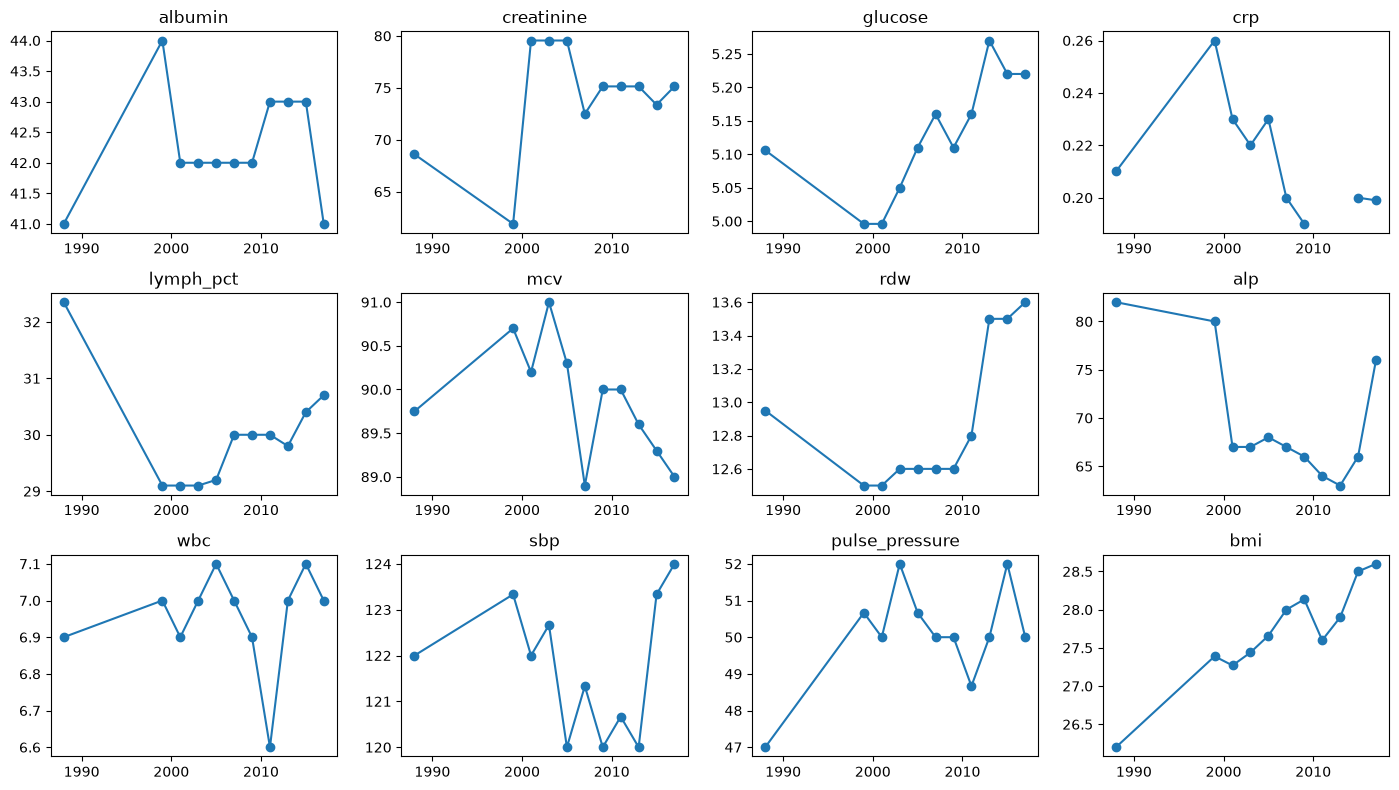

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for ax, c in zip(axes.flat, cols):
    df.groupby('cycle')[c].median().plot(ax=ax, marker='o')
    ax.set_title(c); ax.set_xlabel('')
for ax in list(axes.flat)[len(cols):]: ax.axis('off')
plt.tight_layout()

## PhenoAge vs chronological age

corr 0.921 | mean accel -3.85


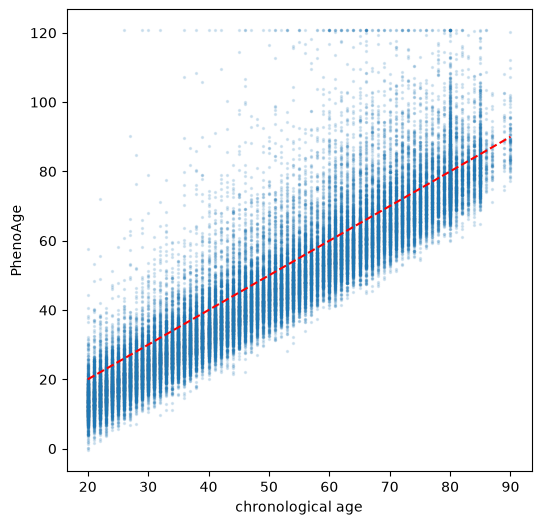

In [4]:
d = df.dropna(subset=MARKERS + ['age']).copy()
d['phenoage'] = phenoage(d)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(d.age, d.phenoage, s=2, alpha=0.15)
ax.plot([20, 90], [20, 90], 'r--')
ax.set_xlabel('chronological age'); ax.set_ylabel('PhenoAge')
print('corr', round(d[['age','phenoage']].corr().iloc[0,1], 3), '| mean accel', round((d.phenoage - d.age).mean(), 2))

## Systolic BP by age and sex

<Axes: xlabel='age_band', ylabel='mean SBP (mmHg)'>

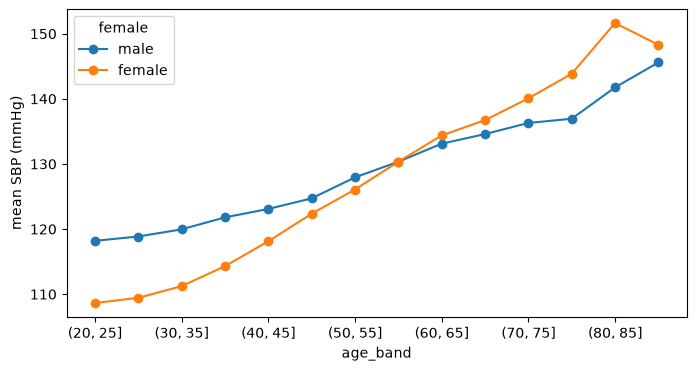

In [5]:
d2 = df.dropna(subset=['sbp', 'age']).assign(age_band=lambda x: pd.cut(x.age, range(20, 95, 5)))
d2.groupby(['age_band', 'female'], observed=True).sbp.mean().unstack().rename(columns={0.0: 'male', 1.0: 'female'}).plot(marker='o', figsize=(8, 4), ylabel='mean SBP (mmHg)')